In [1]:
print("Cassava CNN Project - Group 3")
print("Our project workspace is ready.")

Cassava CNN Project - Group 3
Our project workspace is ready.


In [2]:
import sys
import platform
import os

print("=" * 45)
print("CASSAVA CNN PROJECT - ENVIRONMENT CHECK")
print("=" * 45)

print("\n1. Python version:")
print(sys.version)

print("\n2. Operating environment:")
print(platform.platform())

try:
    import psutil
    ram_gb = psutil.virtual_memory().total / (1024 ** 3)
    available_ram_gb = psutil.virtual_memory().available / (1024 ** 3)
    print(f"\n3. Total RAM: {ram_gb:.2f} GB")
    print(f"   Available RAM: {available_ram_gb:.2f} GB")
except ImportError:
    print("\n3. RAM information is unavailable.")

try:
    import torch

    print("\n4. PyTorch version:")
    print(torch.__version__)

    if torch.cuda.is_available():
        print("\n5. GPU status: AVAILABLE")
        print("GPU name:", torch.cuda.get_device_name(0))
        print("CUDA version:", torch.version.cuda)
    else:
        print("\n5. GPU status: NOT AVAILABLE")
        print("We can continue with CPU for now.")
except ImportError:
    print("\n4. PyTorch is not installed in this environment.")

print("\nEnvironment check completed.")

CASSAVA CNN PROJECT - ENVIRONMENT CHECK

1. Python version:
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

2. Operating environment:
Linux-6.6.159+-x86_64-with-glibc2.39

3. Total RAM: 12.67 GB
   Available RAM: 11.34 GB

4. PyTorch version:
2.14.1+cu130

5. GPU status: AVAILABLE
GPU name: Tesla T4
CUDA version: 13.0

Environment check completed.


In [3]:
import sys
import platform
import os

print("=" * 45)
print("CASSAVA CNN PROJECT - ENVIRONMENT CHECK")
print("=" * 45)

print("\n1. Python version:")
print(sys.version)

print("\n2. Operating environment:")
print(platform.platform())

try:
    import psutil
    ram_gb = psutil.virtual_memory().total / (1024 ** 3)
    available_ram_gb = psutil.virtual_memory().available / (1024 ** 3)
    print(f"\n3. Total RAM: {ram_gb:.2f} GB")
    print(f"   Available RAM: {available_ram_gb:.2f} GB")
except ImportError:
    print("\n3. RAM information is unavailable.")

try:
    import torch

    print("\n4. PyTorch version:")
    print(torch.__version__)

    if torch.cuda.is_available():
        print("\n5. GPU status: AVAILABLE")
        print("GPU name:", torch.cuda.get_device_name(0))
        print("CUDA version:", torch.version.cuda)
    else:
        print("\n5. GPU status: NOT AVAILABLE")
        print("We can continue with CPU for now.")
except ImportError:
    print("\n4. PyTorch is not installed in this environment.")

print("\nEnvironment check completed.")

CASSAVA CNN PROJECT - ENVIRONMENT CHECK

1. Python version:
3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]

2. Operating environment:
Linux-6.6.159+-x86_64-with-glibc2.39

3. Total RAM: 12.67 GB
   Available RAM: 10.94 GB

4. PyTorch version:
2.14.1+cu130

5. GPU status: AVAILABLE
GPU name: Tesla T4
CUDA version: 13.0

Environment check completed.


In [4]:

from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [5]:

import os

project_folder = "/content/drive/MyDrive/Cassava_CNN_Project"

print("Project folder exists:", os.path.exists(project_folder))

if os.path.exists(project_folder):
    print("\nItems inside the project folder:")
    for item in sorted(os.listdir(project_folder)):
        item_path = os.path.join(project_folder, item)

        if os.path.isdir(item_path):
            print(f"[FOLDER] {item}")
        else:
            print(f"[FILE]   {item}")
else:
    print("\nFolder not found. Let's locate it.")
    print("\nFolders in MyDrive:")

    for item in sorted(os.listdir("/content/drive/MyDrive")):
        print(item)

Project folder exists: True

Items inside the project folder:
[FOLDER] EDA_Results
[FOLDER] Submission_2_Results
[FOLDER] cassava leaf disease dataset


In [6]:

import os

def show_structure(folder, max_depth=4, depth=0):
    if depth > max_depth:
        return

    try:
        items = sorted(os.listdir(folder))
    except PermissionError:
        print("  " * depth + "[Cannot access folder]")
        return

    for item in items:
        path = os.path.join(folder, item)

        if os.path.isdir(path):
            print("  " * depth + f"[FOLDER] {item}/")
            if depth < max_depth:
                show_structure(path, max_depth, depth + 1)
        else:
            print("  " * depth + f"[FILE] {item}")

if os.path.exists(project_folder):
    show_structure(project_folder)

[FOLDER] EDA_Results/
  [FILE] cassava_sample_image_grid.png
[FOLDER] Submission_2_Results/
  [FOLDER] checkpoints/
    [FILE] efficientnet_b0_fine_tuned_best.pth
    [FILE] efficientnet_b0_frozen_best.pth
    [FILE] mobilenet_v3_small_fine_tuned_best.pth
    [FILE] mobilenet_v3_small_frozen_best.pth
    [FILE] resnet18_fine_tuned_best.pth
    [FILE] resnet18_frozen_best.pth
  [FILE] dataset_split_indices.npz
  [FOLDER] plots/
    [FILE] all_models_macro_f1_comparison.png
    [FILE] all_models_test_accuracy_comparison.png
    [FILE] efficientnet_b0_fine_tuned_confusion_matrix.png
    [FILE] efficientnet_b0_fine_tuned_training_curves.png
    [FILE] efficientnet_b0_frozen_confusion_matrix.png
    [FILE] efficientnet_b0_frozen_training_curves.png
    [FILE] mobilenet_v3_small_fine_tuned_confusion_matrix.png
    [FILE] mobilenet_v3_small_fine_tuned_training_curves.png
    [FILE] mobilenet_v3_small_frozen_confusion_matrix.png
    [FILE] mobilenet_v3_small_frozen_training_curves.png
    [FIL

In [7]:

import os
from collections import Counter
from PIL import Image

dataset_path = (
    "/content/drive/MyDrive/Cassava_CNN_Project/"
    "cassava leaf disease dataset"
)

image_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}

print("=" * 55)
print("CASSAVA DATASET VERIFICATION")
print("=" * 55)

if not os.path.isdir(dataset_path):
    print("ERROR: Dataset folder not found.")
    print("Expected path:", dataset_path)
    print("Check the folder names in your earlier output.")
else:
    class_folders = sorted(
        name for name in os.listdir(dataset_path)
        if os.path.isdir(os.path.join(dataset_path, name))
    )

    total_images = 0
    total_unreadable = 0
    all_formats = Counter()
    all_dimensions = Counter()
    all_modes = Counter()

    for class_name in class_folders:
        class_path = os.path.join(dataset_path, class_name)

        files = [
            name for name in os.listdir(class_path)
            if os.path.splitext(name)[1].lower() in image_extensions
            and os.path.isfile(os.path.join(class_path, name))
        ]

        readable_count = 0
        unreadable_files = []

        print(f"\nCLASS: {class_name}")
        print("-" * 45)
        print("Image files found:", len(files))

        for filename in files:
            filepath = os.path.join(class_path, filename)
            extension = os.path.splitext(filename)[1].lower()
            all_formats[extension] += 1

            try:
                with Image.open(filepath) as img:
                    img.verify()

                with Image.open(filepath) as img:
                    img.load()
                    all_dimensions[img.size] += 1
                    all_modes[img.mode] += 1

                readable_count += 1

            except Exception:
                unreadable_files.append(filename)

        total_images += len(files)
        total_unreadable += len(unreadable_files)

        print("Readable images:", readable_count)
        print("Unreadable images:", len(unreadable_files))

        if unreadable_files:
            print("Examples of unreadable files:", unreadable_files[:5])

    print("\n" + "=" * 55)
    print("OVERALL DATASET SUMMARY")
    print("=" * 55)
    print("Number of classes:", len(class_folders))
    print("Total image files:", total_images)
    print("Unreadable image files:", total_unreadable)

    print("\nFile formats:")
    for fmt, count in all_formats.most_common():
        print(f"  {fmt}: {count}")

    print("\nImage dimensions (width, height):")
    for dimensions, count in all_dimensions.most_common(10):
        print(f"  {dimensions}: {count} images")

    print("\nImage color modes:")
    for mode, count in all_modes.most_common():
        channels = {"RGB": 3, "RGBA": 4, "L": 1, "CMYK": 4}.get(
            mode, "varies"
        )
        print(f"  {mode}: {count} images; channels: {channels}")

    print("\nVerification completed.")

CASSAVA DATASET VERIFICATION

CLASS: Cassava CB (Cassava Blight)
---------------------------------------------
Image files found: 49
Readable images: 49
Unreadable images: 0

CLASS: Cassava CM (Cassava Mosaic)
---------------------------------------------
Image files found: 88
Readable images: 88
Unreadable images: 0

CLASS: Cassava Healthy leaf
---------------------------------------------
Image files found: 91
Readable images: 91
Unreadable images: 0

OVERALL DATASET SUMMARY
Number of classes: 3
Total image files: 228
Unreadable image files: 0

File formats:
  .jpg: 228

Image dimensions (width, height):
  (512, 512): 228 images

Image color modes:
  RGB: 228 images; channels: 3

Verification completed.


Class distribution:
Cassava CB (Cassava Blight): 49 images (21.49%)
Cassava CM (Cassava Mosaic): 88 images (38.60%)
Cassava Healthy leaf: 91 images (39.91%)


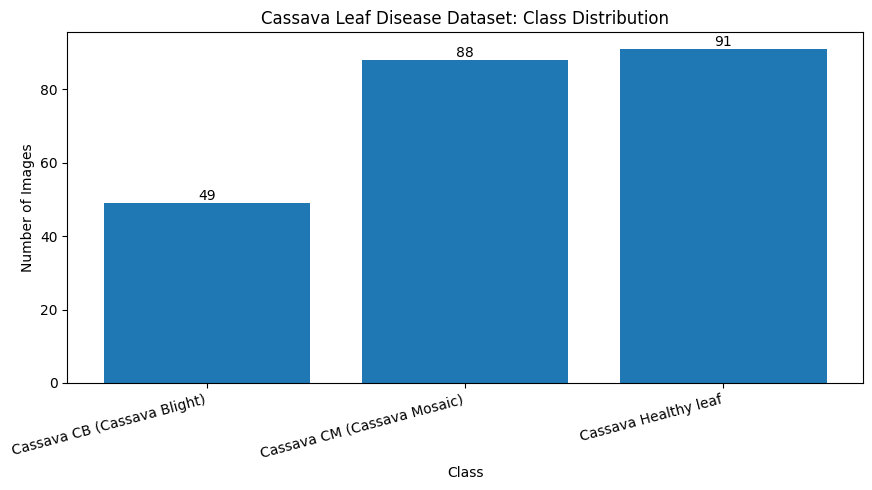

In [8]:

import os
import matplotlib.pyplot as plt

dataset_path = (
    "/content/drive/MyDrive/Cassava_CNN_Project/"
    "cassava leaf disease dataset"
)

class_names = sorted([
    name for name in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, name))
])

class_counts = {}

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)

    image_files = [
        name for name in os.listdir(class_path)
        if os.path.splitext(name)[1].lower()
        in {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp"}
        and os.path.isfile(os.path.join(class_path, name))
    ]

    class_counts[class_name] = len(image_files)

print("Class distribution:")
for name, count in class_counts.items():
    percentage = count / sum(class_counts.values()) * 100
    print(f"{name}: {count} images ({percentage:.2f}%)")

plt.figure(figsize=(9, 5))
bars = plt.bar(
    class_counts.keys(),
    class_counts.values()
)

plt.title("Cassava Leaf Disease Dataset: Class Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=15, ha="right")

for bar, count in zip(bars, class_counts.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(count),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

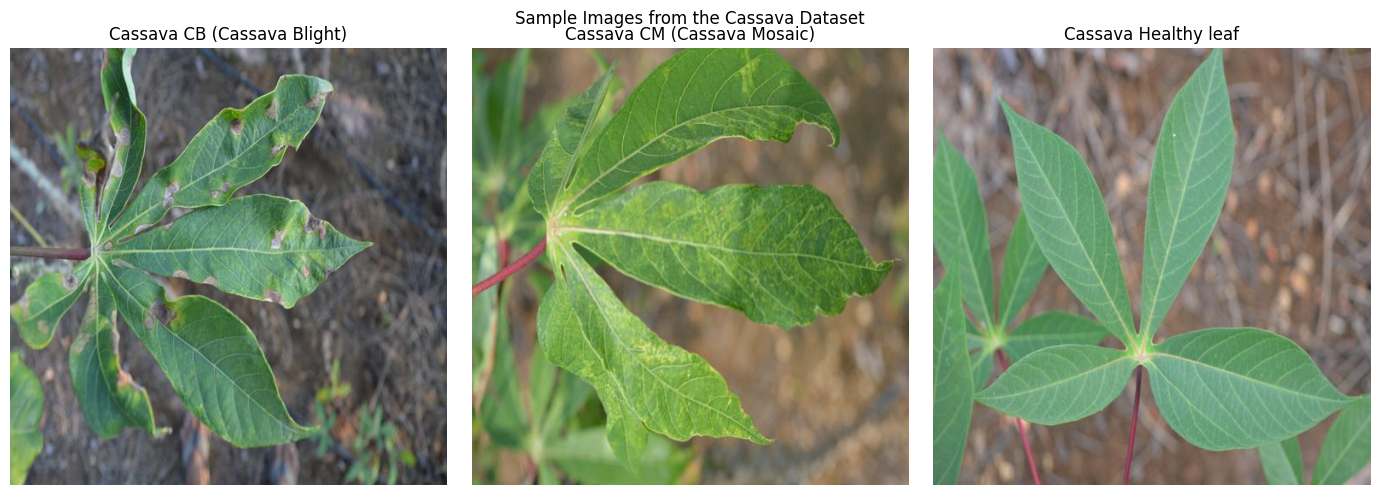

In [9]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = (
    "/content/drive/MyDrive/Cassava_CNN_Project/"
    "cassava leaf disease dataset"
)

random.seed(42)

class_names = sorted([
    name for name in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, name))
])

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, class_name in zip(axes, class_names):
    class_path = os.path.join(dataset_path, class_name)

    files = [
        f for f in os.listdir(class_path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    filename = random.choice(files)

    with Image.open(os.path.join(class_path, filename)) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(class_name)
    ax.axis("off")

plt.suptitle("Sample Images from the Cassava Dataset")
plt.tight_layout()
plt.show()

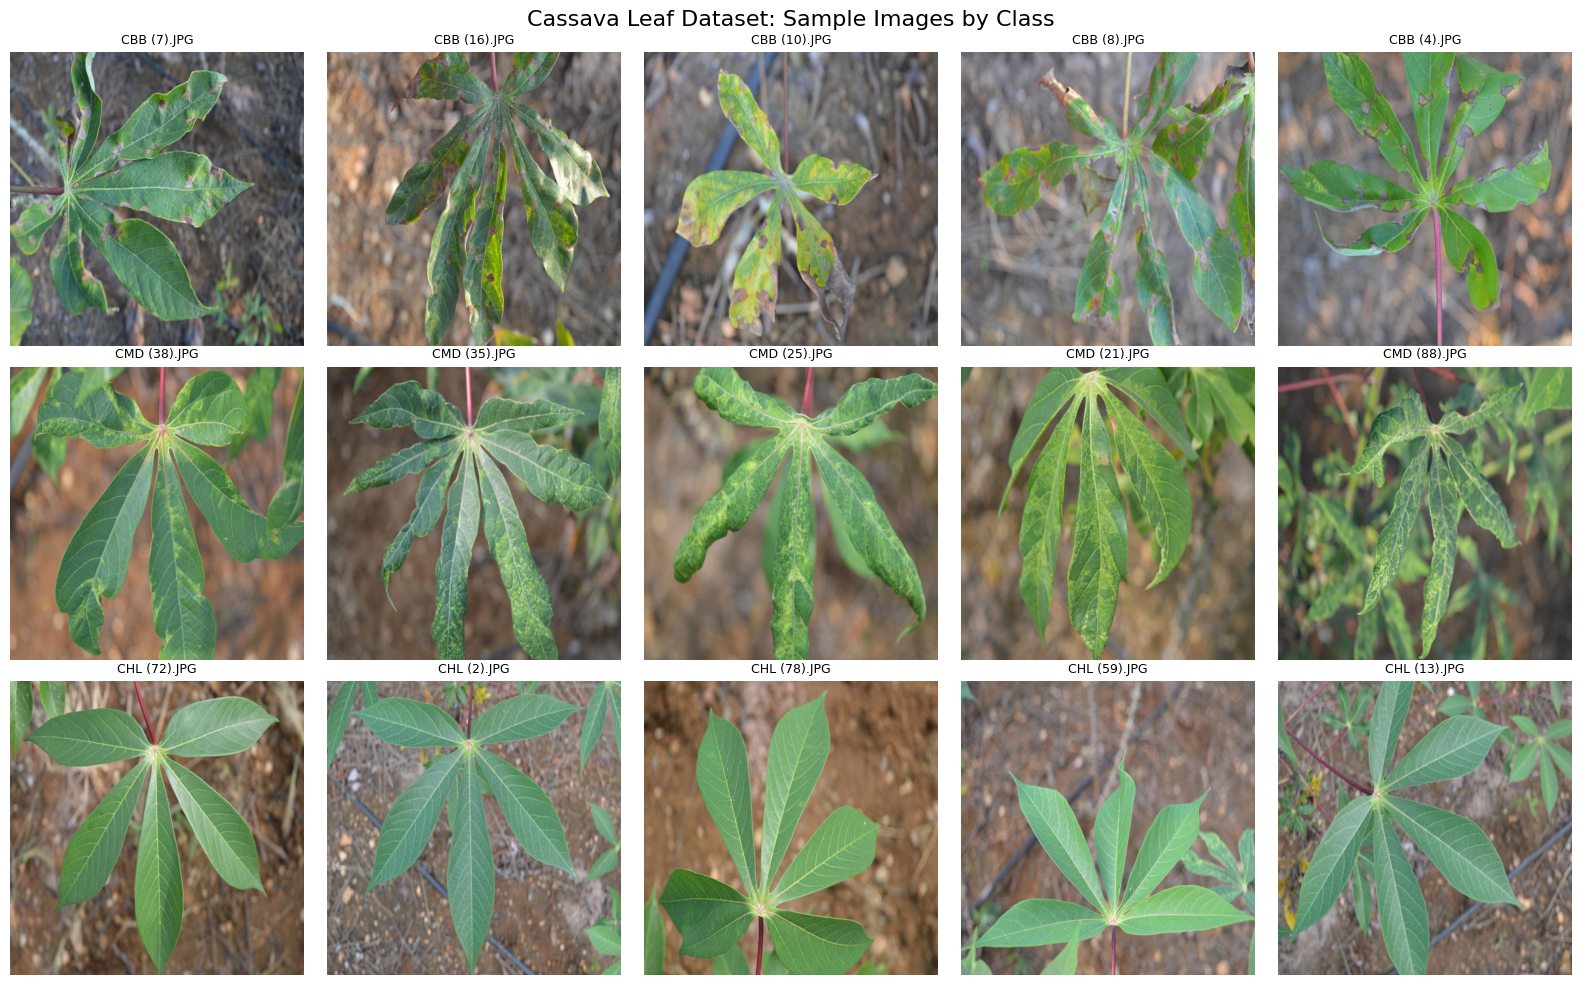

Sample grid saved to: /content/drive/MyDrive/Cassava_CNN_Project/EDA_Results/cassava_sample_image_grid.png


In [10]:

import os
import random
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = (
    "/content/drive/MyDrive/Cassava_CNN_Project/"
    "cassava leaf disease dataset"
)

random.seed(42)

extensions = (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff", ".webp")

class_names = sorted([
    name for name in os.listdir(dataset_path)
    if os.path.isdir(os.path.join(dataset_path, name))
])

fig, axes = plt.subplots(3, 5, figsize=(16, 10))

for row, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)

    image_files = sorted([
        f for f in os.listdir(class_path)
        if f.lower().endswith(extensions)
        and os.path.isfile(os.path.join(class_path, f))
    ])

    samples = random.sample(image_files, min(5, len(image_files)))

    for col, ax in enumerate(axes[row]):
        if col < len(samples):
            image_path = os.path.join(class_path, samples[col])

            with Image.open(image_path) as img:
                ax.imshow(img.convert("RGB"))

            ax.set_title(samples[col], fontsize=9)
        else:
            ax.text(0.5, 0.5, "No image", ha="center", va="center")

        ax.axis("off")

    axes[row, 0].set_ylabel(
        class_name,
        fontsize=10,
        rotation=90,
        labelpad=12
    )

fig.suptitle(
    "Cassava Leaf Dataset: Sample Images by Class",
    fontsize=16
)
plt.tight_layout()

output_dir = "/content/drive/MyDrive/Cassava_CNN_Project/EDA_Results"
os.makedirs(output_dir, exist_ok=True)

grid_path = os.path.join(output_dir, "cassava_sample_image_grid.png")
plt.savefig(grid_path, dpi=200, bbox_inches="tight")
plt.show()

print("Sample grid saved to:", grid_path)

# 1. Dataset Description and Exploratory Data Analysis (EDA)

## 1.1 Dataset Information

**Project title:** Cassava Leaf Disease Classification Using Convolutional Neural Networks (CNN)

**Dataset name:** Cassava Leaf Disease Dataset

**Dataset source:** [Mendeley Data - Cassava Leaf Disease Dataset](https://data.mendeley.com/datasets/3832tx2cb2/1)

**DOI:** 10.17632/3832tx2cb2.1

**License:** Creative Commons Attribution 4.0 International (CC BY 4.0)

**Task type:** Image classification

**Input:** RGB images of cassava leaves.

**Output:** One of three classes: Cassava Blight, Cassava Mosaic, or Healthy Leaf.

## 1.2 Dataset Structure and Statistics

The dataset contains 228 images organized into three class folders.

| Class | Number of images | Percentage |
|---|---:|---:|
| Cassava CB (Cassava Blight) | 49 | 21.49% |
| Cassava CM (Cassava Mosaic) | 88 | 38.60% |
| Cassava Healthy leaf | 91 | 39.91% |
| **Total** | **228** | **100%** |

**Image properties:**
- Total images: 228
- Number of classes: 3
- Image format: JPEG (.jpg)
- Image dimensions: 512 × 512 pixels
- Color mode: RGB (3 color channels)
- Readable images: 228
- Unreadable images: 0

## 1.3 Exploratory Data Analysis Findings

### Class Distribution

The class-distribution chart shows that the dataset is not evenly distributed. Cassava Blight has 49 images, while Cassava Mosaic has 88 images and Healthy Leaf has 91 images.

Cassava Blight is the minority class, representing approximately 21.49% of the dataset. Healthy Leaf and Cassava Mosaic have relatively similar numbers of images. This indicates a moderate class imbalance that should be considered during model training and evaluation.

### Sample Image Inspection

A sample-image grid was created with five images from each class. This visualization allows us to inspect the images and compare the appearance of healthy leaves with leaves affected by the two diseases.

### Image Quality and Format

All 228 image files were readable during verification. Every image was found to have dimensions of 512 × 512 pixels and RGB color mode. No unreadable images were detected in the dataset verification step.

### Preprocessing and Augmentation Considerations

Before training, the images will need to be resized to the input dimensions required by the selected CNN architectures and converted into suitable numerical tensors. Training-set augmentation, such as small rotations, flips, or moderate changes in brightness, may help the model generalize to variations in leaf images.

Any preprocessing and augmentation choices will be documented and applied carefully to avoid introducing unrealistic images. Evaluation images should not receive random training augmentation.

## 1.4 Importance of the Project

Cassava is an important food crop in many regions. Identifying leaf diseases from images is a potential application of computer vision that could support agricultural disease screening. This project investigates whether convolutional neural networks can learn to classify cassava leaf images into the three available categories.

The model's predictions will be evaluated using multiple classification metrics rather than accuracy alone, particularly because the class distribution is imbalanced.

### 1.5 Visual Inspection and Preprocessing Plan

**Visual inspection:** Fifteen sample images were displayed in a grid containing five images from each of the three classes. During the initial inspection, no obvious image-quality problems were noticed in the displayed samples.

**Class similarity:** The visual inspection provides an initial overview of the three classes. Further evaluation is required to determine how frequently disease symptoms overlap visually and whether the model confuses similar examples.

**Class imbalance:** Cassava Blight contains 49 images, compared with 88 Cassava Mosaic images and 91 Healthy Leaf images. Stratified data splitting will be used to preserve class representation. Class-wise precision, recall, and F1-score will be reported alongside accuracy.

**Preprocessing plan:** Images will be resized to match each model's input requirements, converted to RGB where necessary, and normalized according to the selected architecture.

**Augmentation plan:** Training images may undergo modest random rotations, horizontal or vertical flips where appropriate, and limited brightness variation. Validation and test images will not receive random training augmentation. The effects of these choices will be evaluated during model development.

# 2. Related Work: Research on Cassava Leaf Disease Classification

| No. | Paper (author, year) | Dataset used | Model(s) | Approach | Reported result | Reference |
|---|---|---|---|---|---|---|
| 1 | Ramcharan et al. (2017), *Deep Learning for Image-Based Cassava Disease Detection* | Field photographs collected in Tanzania; original and cropped-leaf datasets | InceptionV3 with alternative final-layer classifiers, including SVM and k-NN | Transfer learning using an ImageNet-pretrained CNN; evaluated different training/test splits | Up to 93% overall accuracy on the cropped-leaf dataset with an 80:10 train:test split and 10% validation | [Read paper](https://doi.org/10.3389/fpls.2017.01852) |
| 2 | *Enhanced Convolutional Neural Network Model for Cassava Leaf Disease Identification and Classification* (2022) | Online cassava image dataset containing 6,256 images across five classes | Standard CNN and enhanced CNN (ECNN) | Compared CNN architectures and examined the effect of balancing the dataset | The paper reports 99.3% accuracy for the balanced dataset; this result should be interpreted in the context of its experimental setup | [Read paper](https://www.mdpi.com/2227-7390/10/4/580) |
| 3 | *Hybrid Ensemble – Deep Transfer Model for Early Cassava Leaf Disease Classification* (2024) | Cassava leaf disease image dataset used for five-class and two-class experiments | Ensembles combining InceptionV3, DenseNet-BC-121-32, Xception, and ResNet variants | Transfer learning, data augmentation, and ensemble learning | The authors report 88.83% accuracy for five-class classification and 97.89% for two-class classification using the reported ensemble approach | [Read paper](https://doi.org/10.1016/j.heliyon.2024.e36097) |

## 2.1 Related-Work Summary

Previous studies show that CNNs and transfer learning can be applied to cassava leaf disease classification. Transfer learning reuses visual features learned from large image datasets, while data augmentation can help address limited or imbalanced training data. Ensemble methods combine predictions from multiple models and may improve performance, although they can require more computation.

The reported accuracy values cannot be compared directly without considering differences in datasets, class definitions, data splits, and evaluation procedures. The present project uses a smaller dataset containing 228 images and three classes: Cassava Blight, Cassava Mosaic, and Healthy Leaf.

Our project will investigate CNN-based classification on this dataset and evaluate performance using accuracy, precision, recall, F1-score, and a confusion matrix. Experimental results will be reported only after training and testing have been completed.

# Cassava Leaf Disease Classification - Submission 2
## Pretrained CNN Models With and Without Fine-Tuning

**Group:** 3

**Project:** Cassava Leaf Disease Classification Using Convolutional Neural Networks

### Objective
The objective of this submission is to compare pretrained CNN architectures for classifying cassava leaf images into three classes:

1. Cassava Blight
2. Cassava Mosaic
3. Cassava Healthy Leaf

### Models
- ResNet18
- MobileNetV3-Small
- EfficientNet-B0

### Experimental Conditions
Each architecture will be evaluated in two conditions:

1. Frozen pretrained feature extractor: only the new final classification layer is trained.
2. Fine-tuned pretrained model: all model layers are allowed to learn from the cassava dataset.

### Evaluation
Each experiment will use:
- 30 training epochs
- Training and validation accuracy curves
- Training and validation loss curves
- Classification report
- Test confusion matrix
- Accuracy, precision, recall and F1-score
- Training time and testing time

The dataset will be divided into training, validation and testing subsets using stratified splitting.

In [11]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [12]:
import os
import random
import time
import copy
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim

import torchvision
from torchvision import datasets, transforms
from torchvision.models import (
    resnet18,
    ResNet18_Weights,
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights,
    efficientnet_b0,
    EfficientNet_B0_Weights
)

from torch.utils.data import DataLoader, Subset

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("All libraries imported successfully.")
print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Selected device:", device)

if device.type == "cuda":
    print("GPU name:", torch.cuda.get_device_name(0))

All libraries imported successfully.
PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
NumPy: 2.4.6
Pandas: 2.2.3
Selected device: cuda
GPU name: Tesla T4


In [13]:
DATA_DIR = Path(
    "/content/drive/MyDrive/Cassava_CNN_Project/"
    "cassava leaf disease dataset"
)

if not DATA_DIR.exists():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR}\n"
        "Please check the folder name and Google Drive location."
    )

print("Dataset folder found:", DATA_DIR)

dataset_check = datasets.ImageFolder(DATA_DIR)

class_names = dataset_check.classes
class_to_idx = dataset_check.class_to_idx
targets = np.array(dataset_check.targets)

print("\nCLASS INFORMATION")
print("------------------------------")

for class_name, count in zip(
    class_names,
    np.bincount(targets, minlength=len(class_names))
):
    print(f"{class_name}: {count} images")

print("\nTotal images:", len(dataset_check))
print("Total classes:", len(class_names))
print("Class mapping:", class_to_idx)

assert len(class_names) == 3, "Expected exactly three classes."

if len(dataset_check) != 228:
    print(
        "WARNING: Expected 228 images based on Submission 1. "
        "Please check the dataset folder."
    )
else:
    print("\nDataset count matches Submission 1.")

Dataset folder found: /content/drive/MyDrive/Cassava_CNN_Project/cassava leaf disease dataset

CLASS INFORMATION
------------------------------
Cassava CB (Cassava Blight): 49 images
Cassava CM (Cassava Mosaic): 88 images
Cassava Healthy leaf: 91 images

Total images: 228
Total classes: 3
Class mapping: {'Cassava CB (Cassava Blight)': 0, 'Cassava CM (Cassava Mosaic)': 1, 'Cassava Healthy leaf': 2}

Dataset count matches Submission 1.


In [14]:
SEED = 42

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

all_indices = np.arange(len(dataset_check))


train_indices, temporary_indices = train_test_split(
    all_indices,
    test_size=0.30,
    random_state=SEED,
    stratify=targets
)

temporary_targets = targets[temporary_indices]

val_indices, test_indices = train_test_split(
    temporary_indices,
    test_size=0.50,
    random_state=SEED,
    stratify=temporary_targets
)

print("DATASET SPLIT")
print("------------------------------")
print("Training images:", len(train_indices))
print("Validation images:", len(val_indices))
print("Testing images:", len(test_indices))
print("Total:", len(train_indices) + len(val_indices) + len(test_indices))

assert len(set(train_indices) & set(val_indices)) == 0
assert len(set(train_indices) & set(test_indices)) == 0
assert len(set(val_indices) & set(test_indices)) == 0

print("\nNo overlapping images found.")

DATASET SPLIT
------------------------------
Training images: 159
Validation images: 34
Testing images: 35
Total: 228

No overlapping images found.


In [15]:
split_counts = []

for split_name, indices in [
    ("Training", train_indices),
    ("Validation", val_indices),
    ("Testing", test_indices)
]:
    counts = np.bincount(
        targets[indices],
        minlength=len(class_names)
    )

    for class_name, count in zip(class_names, counts):
        split_counts.append({
            "Dataset": split_name,
            "Class": class_name,
            "Images": int(count)
        })

split_df = pd.DataFrame(split_counts)

display(
    split_df.pivot(
        index="Class",
        columns="Dataset",
        values="Images"
    )
)

Dataset,Testing,Training,Validation
Class,,,
Cassava CB (Cassava Blight),7,34,8
Cassava CM (Cassava Mosaic),14,61,13
Cassava Healthy leaf,14,64,13


In [16]:
SPLIT_DIR = Path(
    "/content/drive/MyDrive/Cassava_CNN_Project/"
    "Submission_2_Results"
)

SPLIT_DIR.mkdir(parents=True, exist_ok=True)

np.savez(
    SPLIT_DIR / "dataset_split_indices.npz",
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_indices
)

print("Dataset split saved successfully.")

Dataset split saved successfully.


In [17]:
IMAGE_SIZE = 224
BATCH_SIZE = 16

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),

    transforms.ColorJitter(
        brightness=0.1,
        contrast=0.1,
        saturation=0.1
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

evaluation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=IMAGENET_MEAN,
        std=IMAGENET_STD
    )
])

print("Image transformations prepared.")

Image transformations prepared.


In [18]:
train_full_dataset = datasets.ImageFolder(
    DATA_DIR,
    transform=train_transform
)

val_full_dataset = datasets.ImageFolder(
    DATA_DIR,
    transform=evaluation_transform
)

test_full_dataset = datasets.ImageFolder(
    DATA_DIR,
    transform=evaluation_transform
)

assert train_full_dataset.class_to_idx == class_to_idx
assert val_full_dataset.class_to_idx == class_to_idx
assert test_full_dataset.class_to_idx == class_to_idx


def create_data_loaders(seed=42):

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_dataset = Subset(
        train_full_dataset,
        train_indices.tolist()
    )

    val_dataset = Subset(
        val_full_dataset,
        val_indices.tolist()
    )

    test_dataset = Subset(
        test_full_dataset,
        test_indices.tolist()
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=2,
        pin_memory=True,
        generator=generator
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    return train_loader, val_loader, test_loader


train_loader, val_loader, test_loader = create_data_loaders(SEED)

print("DataLoaders created successfully.")

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

DataLoaders created successfully.
Training batches: 10
Validation batches: 3
Testing batches: 3


In [19]:
training_labels = targets[train_indices]

training_class_counts = np.bincount(
    training_labels,
    minlength=len(class_names)
)

class_weights_array = (
    len(train_indices) /
    (len(class_names) * training_class_counts)
)

class_weights = torch.tensor(
    class_weights_array,
    dtype=torch.float32
).to(device)

print("Training class counts:", training_class_counts)
print("Class weights:", class_weights)

print("\nClass weights prepared.")

Training class counts: [34 61 64]
Class weights: tensor([1.5588, 0.8689, 0.8281], device='cuda:0')

Class weights prepared.


In [20]:
NUM_CLASSES = len(class_names)


def build_model(architecture, fine_tune=False):

    if architecture == "resnet18":

        model = resnet18(
            weights=ResNet18_Weights.DEFAULT
        )

        model.fc = nn.Linear(
            model.fc.in_features,
            NUM_CLASSES
        )

        output_layer = model.fc

    elif architecture == "mobilenet_v3_small":

        model = mobilenet_v3_small(
            weights=MobileNet_V3_Small_Weights.DEFAULT
        )

        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features,
            NUM_CLASSES
        )

        output_layer = model.classifier[-1]

    elif architecture == "efficientnet_b0":

        model = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        model.classifier[-1] = nn.Linear(
            model.classifier[-1].in_features,
            NUM_CLASSES
        )

        output_layer = model.classifier[-1]

    else:
        raise ValueError(
            f"Unknown architecture: {architecture}"
        )

    # Set trainable parameters
    if fine_tune:

        for parameter in model.parameters():
            parameter.requires_grad = True

    else:

        for parameter in model.parameters():
            parameter.requires_grad = False

        for parameter in output_layer.parameters():
            parameter.requires_grad = True

    return model, output_layer


print("Model-building function created.")

Model-building function created.


In [21]:
test_model_names = [
    "resnet18",
    "mobilenet_v3_small",
    "efficientnet_b0"
]

for model_name in test_model_names:

    temporary_model, _ = build_model(
        model_name,
        fine_tune=False
    )

    temporary_model = temporary_model.to(device)

    print(
        model_name,
        "initialized successfully."
    )

    del temporary_model

torch.cuda.empty_cache()

resnet18 initialized successfully.
mobilenet_v3_small initialized successfully.
efficientnet_b0 initialized successfully.


In [22]:
def set_model_training_mode(model, architecture, fine_tune):

    if fine_tune:

        model.train()

        for module in model.modules():
            if isinstance(
                module,
                nn.modules.batchnorm._BatchNorm
            ):
                module.eval()

    else:

        model.eval()

        if architecture == "resnet18":
            model.fc.train()
        else:
            model.classifier.train()


def run_epoch(
    model,
    loader,
    criterion,
    architecture,
    fine_tune,
    is_training,
    optimizer=None
):

    if is_training:

        set_model_training_mode(
            model,
            architecture,
            fine_tune
        )

    else:
        model.eval()

    total_loss = 0.0
    correct_predictions = 0
    total_images = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        if is_training:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_training):

            outputs = model(images)

            loss = criterion(
                outputs,
                labels
            )

            if is_training:
                loss.backward()
                optimizer.step()

        batch_size = labels.size(0)

        total_loss += loss.item() * batch_size

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct_predictions += (
            predictions == labels
        ).sum().item()

        total_images += batch_size

    average_loss = total_loss / total_images

    accuracy = correct_predictions / total_images

    return average_loss, accuracy


print("Training and validation functions are ready.")

Training and validation functions are ready.


In [23]:
def plot_training_history(
    history,
    architecture,
    mode,
    save_path
):

    epochs = range(1, len(history["train_loss"]) + 1)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Accuracy graph
    axes[0].plot(
        epochs,
        history["train_accuracy"],
        label="Training Accuracy"
    )

    axes[0].plot(
        epochs,
        history["val_accuracy"],
        label="Validation Accuracy"
    )

    axes[0].set_title(
        f"{architecture} - {mode}: Accuracy"
    )

    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    # Loss graph
    axes[1].plot(
        epochs,
        history["train_loss"],
        label="Training Loss"
    )

    axes[1].plot(
        epochs,
        history["val_loss"],
        label="Validation Loss"
    )

    axes[1].set_title(
        f"{architecture} - {mode}: Loss"
    )

    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()

    plt.savefig(
        save_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Training curves saved:", save_path)

In [24]:
def evaluate_model(
    model,
    test_loader,
    architecture,
    mode,
    save_directory
):

    model.eval()

    true_labels = []
    predicted_labels = []

    if device.type == "cuda":
        torch.cuda.synchronize()

    start_time = time.perf_counter()

    with torch.inference_mode():

        for images, labels in test_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            true_labels.extend(
                labels.numpy().tolist()
            )

            predicted_labels.extend(
                predictions.cpu().numpy().tolist()
            )

    if device.type == "cuda":
        torch.cuda.synchronize()

    testing_time = time.perf_counter() - start_time

    # Classification metrics
    test_accuracy = accuracy_score(
        true_labels,
        predicted_labels
    )

    macro_precision = precision_score(
        true_labels,
        predicted_labels,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    macro_recall = recall_score(
        true_labels,
        predicted_labels,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    macro_f1 = f1_score(
        true_labels,
        predicted_labels,
        labels=np.arange(NUM_CLASSES),
        average="macro",
        zero_division=0
    )

    weighted_f1 = f1_score(
        true_labels,
        predicted_labels,
        labels=np.arange(NUM_CLASSES),
        average="weighted",
        zero_division=0
    )

    report_text = classification_report(
        true_labels,
        predicted_labels,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        zero_division=0
    )

    report_dict = classification_report(
        true_labels,
        predicted_labels,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    print("\nCLASSIFICATION REPORT")
    print("=" * 65)
    print(report_text)

    print("TEST METRICS")
    print("=" * 65)
    print(f"Accuracy:           {test_accuracy:.4f}")
    print(f"Macro Precision:    {macro_precision:.4f}")
    print(f"Macro Recall:       {macro_recall:.4f}")
    print(f"Macro F1-score:     {macro_f1:.4f}")
    print(f"Weighted F1-score:  {weighted_f1:.4f}")
    print(f"Testing Time:       {testing_time:.2f} seconds")

    cm = confusion_matrix(
        true_labels,
        predicted_labels,
        labels=np.arange(NUM_CLASSES)
    )

    fig, ax = plt.subplots(figsize=(8, 6))

    display_matrix = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    display_matrix.plot(
        ax=ax,
        cmap="Blues",
        values_format="d",
        colorbar=False
    )

    plt.title(
        f"{architecture} - {mode}: Test Confusion Matrix"
    )

    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()

    matrix_path = (
        save_directory /
        f"{architecture}_{mode}_confusion_matrix.png"
    )

    plt.savefig(
        matrix_path,
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()

    print("Confusion matrix saved:", matrix_path)

    return {
        "accuracy": float(test_accuracy),
        "macro_precision": float(macro_precision),
        "macro_recall": float(macro_recall),
        "macro_f1": float(macro_f1),
        "weighted_f1": float(weighted_f1),
        "testing_time_seconds": float(testing_time),
        "classification_report": report_text,
        "classification_report_dict": report_dict,
        "confusion_matrix": cm.tolist()
    }


print("Evaluation function created.")

Evaluation function created.


In [25]:
OUTPUT_DIR = Path(
    "/content/drive/MyDrive/Cassava_CNN_Project/"
    "Submission_2_Results"
)

CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
PLOT_DIR = OUTPUT_DIR / "plots"
REPORT_DIR = OUTPUT_DIR / "reports"

for directory in [
    OUTPUT_DIR,
    CHECKPOINT_DIR,
    PLOT_DIR,
    REPORT_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Output directories prepared.")

print("Checkpoints:", CHECKPOINT_DIR)
print("Plots:", PLOT_DIR)
print("Reports:", REPORT_DIR)

Output directories prepared.
Checkpoints: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/checkpoints
Plots: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots
Reports: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/reports


In [32]:
EPOCHS = 30

WEIGHT_DECAY = 0.0001

FROZEN_LEARNING_RATE = 0.001
FINE_TUNING_LEARNING_RATE = 0.0001


def run_experiment(architecture, fine_tune):

    mode = (
        "fine_tuned"
        if fine_tune
        else "frozen"
    )

    experiment_name = f"{architecture}_{mode}"

    print("\n")
    print("=" * 75)
    print("STARTING EXPERIMENT:", experiment_name)
    print("=" * 75)

    set_seed(SEED)

    train_loader, val_loader, test_loader = (
        create_data_loaders(SEED)
    )

    model, output_layer = build_model(
        architecture,
        fine_tune=fine_tune
    )

    model = model.to(device)

    trainable_parameters = [
        parameter
        for parameter in model.parameters()
        if parameter.requires_grad
    ]

    print(
        "Trainable parameters:",
        sum(p.numel() for p in trainable_parameters)
    )

    learning_rate = (
        FINE_TUNING_LEARNING_RATE
        if fine_tune
        else FROZEN_LEARNING_RATE
    )

    optimizer = optim.AdamW(
        trainable_parameters,
        lr=learning_rate,
        weight_decay=WEIGHT_DECAY
    )

    criterion = nn.CrossEntropyLoss(
        weight=class_weights
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=4
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_loss = float("inf")
    best_epoch = 0

    checkpoint_path = (
        CHECKPOINT_DIR /
        f"{experiment_name}_best.pth"
    )

    total_training_time = 0.0

    for epoch in range(1, EPOCHS + 1):

        if device.type == "cuda":
            torch.cuda.synchronize()

        start_training = time.perf_counter()

        train_loss, train_accuracy = run_epoch(
            model=model,
            loader=train_loader,
            criterion=criterion,
            architecture=architecture,
            fine_tune=fine_tune,
            is_training=True,
            optimizer=optimizer
        )

        if device.type == "cuda":
            torch.cuda.synchronize()

        total_training_time += (
            time.perf_counter() - start_training
        )

        val_loss, val_accuracy = run_epoch(
            model=model,
            loader=val_loader,
            criterion=criterion,
            architecture=architecture,
            fine_tune=fine_tune,
            is_training=False
        )

        scheduler.step(val_loss)

        history["train_loss"].append(
            float(train_loss)
        )

        history["val_loss"].append(
            float(val_loss)
        )

        history["train_accuracy"].append(
            float(train_accuracy)
        )

        history["val_accuracy"].append(
            float(val_accuracy)
        )

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch [{epoch:02d}/{EPOCHS}] "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Train Acc: {train_accuracy:.4f} | "
            f"Val Acc: {val_accuracy:.4f} | "
            f"LR: {current_lr:.6f}"
        )

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch

            torch.save(
                model.state_dict(),
                checkpoint_path
            )

    print("\nTraining completed.")

    print("Best epoch:", best_epoch)
    print("Best validation loss:", best_val_loss)
    print(
        "Training time:",
        f"{total_training_time:.2f} seconds"
    )

    # Load the best validation checkpoint before testing.
    best_state = torch.load(
        checkpoint_path,
        map_location=device,
        weights_only=True
    )

    model.load_state_dict(best_state)

    print("\nEvaluating on the held-out test set...")

    evaluation = evaluate_model(
        model=model,
        test_loader=test_loader,
        architecture=architecture,
        mode=mode,
        save_directory=PLOT_DIR
    )

    # Save accuracy and loss graphs.
    curve_path = (
        PLOT_DIR /
        f"{experiment_name}_training_curves.png"
    )

    plot_training_history(
        history,
        architecture,
        mode,
        curve_path
    )

    # Save the detailed report.
    report_path = (
        REPORT_DIR /
        f"{experiment_name}_classification_report.txt"
    )

    with open(
        report_path,
        "w",
        encoding="utf-8"
    ) as file:

        file.write(evaluation["classification_report"])

    # Save detailed machine-readable metrics.
    details = {
        "architecture": architecture,
        "mode": mode,
        "epochs": EPOCHS,
        "best_epoch": best_epoch,
        "best_validation_loss": float(best_val_loss),
        "best_validation_accuracy": float(
            history["val_accuracy"][best_epoch - 1]
        ),
        "training_time_seconds": float(total_training_time),
        "test_metrics": evaluation
    }

    json_path = (
        REPORT_DIR /
        f"{experiment_name}_results.json"
    )

    with open(
        json_path,
        "w",
        encoding="utf-8"
    ) as file:

        json.dump(
            details,
            file,
            indent=4
        )

    result_row = {
        "Architecture": architecture,
        "Mode": mode,
        "Epochs": EPOCHS,
        "Best Epoch": best_epoch,
        "Best Validation Loss": best_val_loss,
        "Best Validation Accuracy": history["val_accuracy"][best_epoch - 1],
        "Test Accuracy": evaluation["accuracy"],
        "Macro Precision": evaluation["macro_precision"],
        "Macro Recall": evaluation["macro_recall"],
        "Macro F1": evaluation["macro_f1"],
        "Weighted F1": evaluation["weighted_f1"],
        "Training Time (seconds)": total_training_time,
        "Testing Time (seconds)": evaluation["testing_time_seconds"]
    }

    print("\nExperiment finished:", experiment_name)

    del model
    torch.cuda.empty_cache()

    return result_row


print("Complete experiment runner created.")

Complete experiment runner created.




STARTING EXPERIMENT: resnet18_frozen
Trainable parameters: 1539
Epoch [01/30] Train Loss: 1.0723 | Val Loss: 0.8905 | Train Acc: 0.4528 | Val Acc: 0.8529 | LR: 0.001000
Epoch [02/30] Train Loss: 0.8652 | Val Loss: 0.7210 | Train Acc: 0.6352 | Val Acc: 0.8824 | LR: 0.001000
Epoch [03/30] Train Loss: 0.6443 | Val Loss: 0.6552 | Train Acc: 0.9057 | Val Acc: 0.8529 | LR: 0.001000
Epoch [04/30] Train Loss: 0.5494 | Val Loss: 0.5056 | Train Acc: 0.9057 | Val Acc: 0.9412 | LR: 0.001000
Epoch [05/30] Train Loss: 0.4894 | Val Loss: 0.4539 | Train Acc: 0.8805 | Val Acc: 0.9706 | LR: 0.001000
Epoch [06/30] Train Loss: 0.4087 | Val Loss: 0.4469 | Train Acc: 0.9371 | Val Acc: 0.9412 | LR: 0.001000
Epoch [07/30] Train Loss: 0.3733 | Val Loss: 0.3584 | Train Acc: 0.9434 | Val Acc: 0.9706 | LR: 0.001000
Epoch [08/30] Train Loss: 0.3249 | Val Loss: 0.3325 | Train Acc: 0.9623 | Val Acc: 0.9706 | LR: 0.001000
Epoch [09/30] Train Loss: 0.3018 | Val Loss: 0.3226 | Train Acc: 0.9560 | Val Acc: 0.9706 | LR

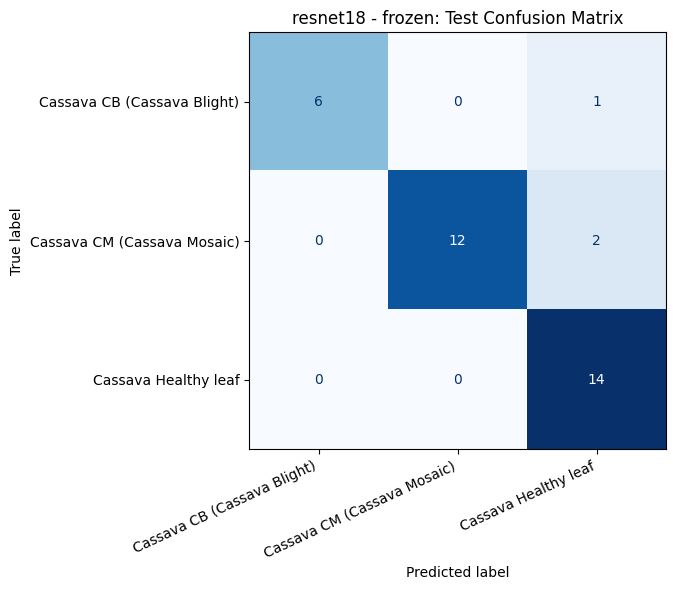

Confusion matrix saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/resnet18_frozen_confusion_matrix.png


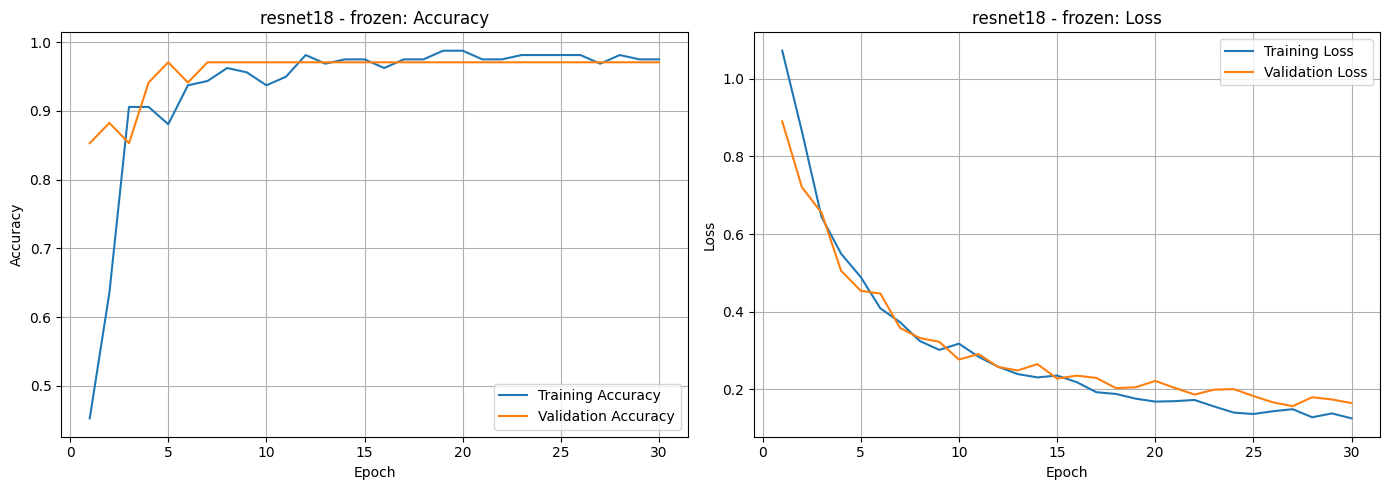

Training curves saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/resnet18_frozen_training_curves.png

Experiment finished: resnet18_frozen

Progress: 1 / 6 experiments completed.


STARTING EXPERIMENT: resnet18_fine_tuned
Trainable parameters: 11178051
Epoch [01/30] Train Loss: 1.1032 | Val Loss: 0.7137 | Train Acc: 0.4654 | Val Acc: 0.8235 | LR: 0.000100
Epoch [02/30] Train Loss: 0.4277 | Val Loss: 0.3669 | Train Acc: 0.8805 | Val Acc: 0.8529 | LR: 0.000100
Epoch [03/30] Train Loss: 0.3729 | Val Loss: 0.2758 | Train Acc: 0.8742 | Val Acc: 0.8235 | LR: 0.000100
Epoch [04/30] Train Loss: 0.2003 | Val Loss: 0.0227 | Train Acc: 0.9119 | Val Acc: 1.0000 | LR: 0.000100
Epoch [05/30] Train Loss: 0.0982 | Val Loss: 0.0411 | Train Acc: 0.9811 | Val Acc: 1.0000 | LR: 0.000100
Epoch [06/30] Train Loss: 0.0730 | Val Loss: 0.0052 | Train Acc: 0.9811 | Val Acc: 1.0000 | LR: 0.000100
Epoch [07/30] Train Loss: 0.0465 | Val Loss: 0.0050 | Train Acc: 0.9874 | Val Acc: 1.0000

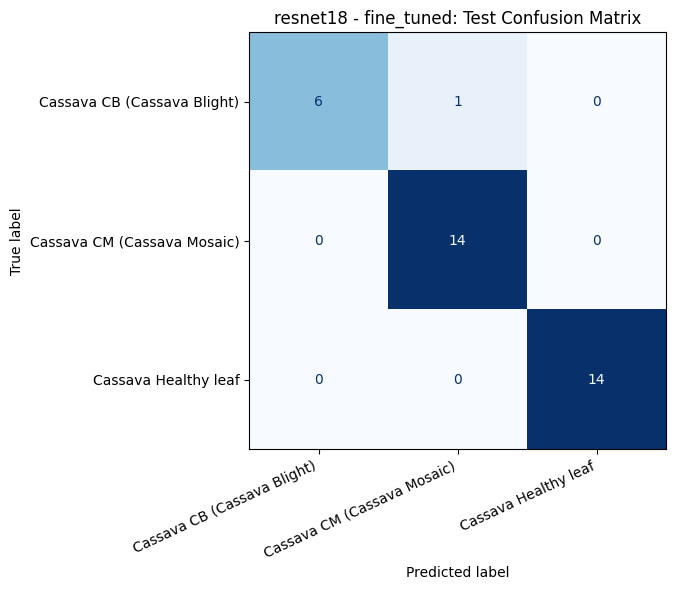

Confusion matrix saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/resnet18_fine_tuned_confusion_matrix.png


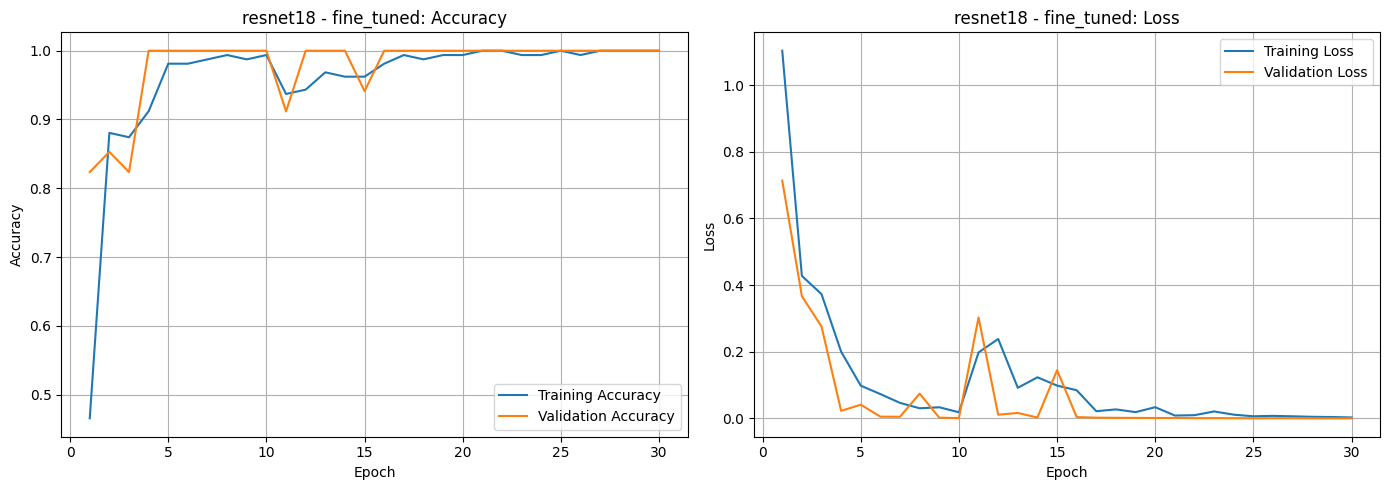

Training curves saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/resnet18_fine_tuned_training_curves.png

Experiment finished: resnet18_fine_tuned

Progress: 2 / 6 experiments completed.


STARTING EXPERIMENT: mobilenet_v3_small_frozen
Trainable parameters: 3075
Epoch [01/30] Train Loss: 0.9249 | Val Loss: 0.6521 | Train Acc: 0.6226 | Val Acc: 0.8235 | LR: 0.001000
Epoch [02/30] Train Loss: 0.5316 | Val Loss: 0.4032 | Train Acc: 0.8805 | Val Acc: 1.0000 | LR: 0.001000
Epoch [03/30] Train Loss: 0.3484 | Val Loss: 0.2979 | Train Acc: 0.9434 | Val Acc: 1.0000 | LR: 0.001000
Epoch [04/30] Train Loss: 0.2624 | Val Loss: 0.2375 | Train Acc: 0.9748 | Val Acc: 1.0000 | LR: 0.001000
Epoch [05/30] Train Loss: 0.2093 | Val Loss: 0.1874 | Train Acc: 0.9623 | Val Acc: 1.0000 | LR: 0.001000
Epoch [06/30] Train Loss: 0.1723 | Val Loss: 0.1696 | Train Acc: 0.9748 | Val Acc: 1.0000 | LR: 0.001000
Epoch [07/30] Train Loss: 0.1711 | Val Loss: 0.1491 | Train Acc: 0.9686 | Val A

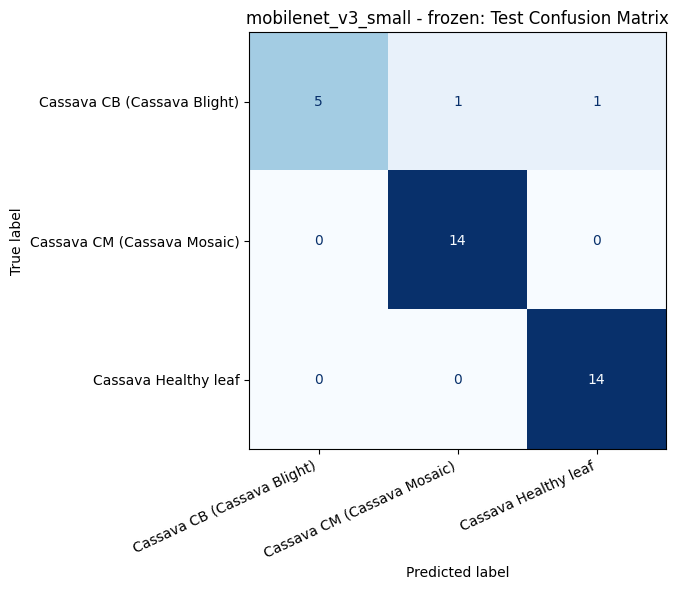

Confusion matrix saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/mobilenet_v3_small_frozen_confusion_matrix.png


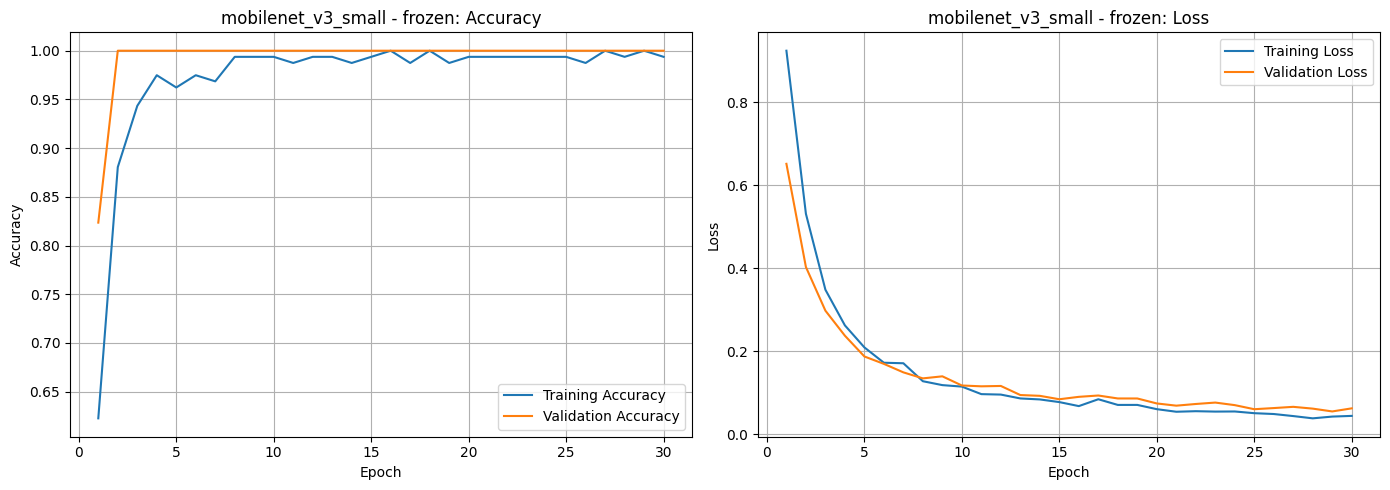

Training curves saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/mobilenet_v3_small_frozen_training_curves.png

Experiment finished: mobilenet_v3_small_frozen

Progress: 3 / 6 experiments completed.


STARTING EXPERIMENT: mobilenet_v3_small_fine_tuned
Trainable parameters: 1520931
Epoch [01/30] Train Loss: 0.9129 | Val Loss: 0.6108 | Train Acc: 0.6667 | Val Acc: 0.9412 | LR: 0.000100
Epoch [02/30] Train Loss: 0.4047 | Val Loss: 0.1872 | Train Acc: 0.9434 | Val Acc: 1.0000 | LR: 0.000100
Epoch [03/30] Train Loss: 0.1704 | Val Loss: 0.0415 | Train Acc: 0.9560 | Val Acc: 1.0000 | LR: 0.000100
Epoch [04/30] Train Loss: 0.0839 | Val Loss: 0.0300 | Train Acc: 0.9811 | Val Acc: 1.0000 | LR: 0.000100
Epoch [05/30] Train Loss: 0.0487 | Val Loss: 0.0687 | Train Acc: 0.9811 | Val Acc: 1.0000 | LR: 0.000100
Epoch [06/30] Train Loss: 0.0432 | Val Loss: 0.0069 | Train Acc: 0.9937 | Val Acc: 1.0000 | LR: 0.000100
Epoch [07/30] Train Loss: 0.0536 | Val Loss: 0.0102 | Train 

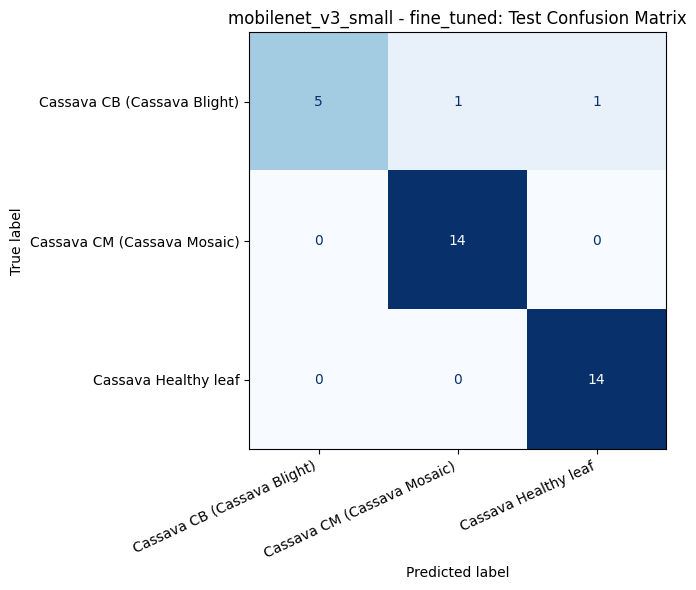

Confusion matrix saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/mobilenet_v3_small_fine_tuned_confusion_matrix.png


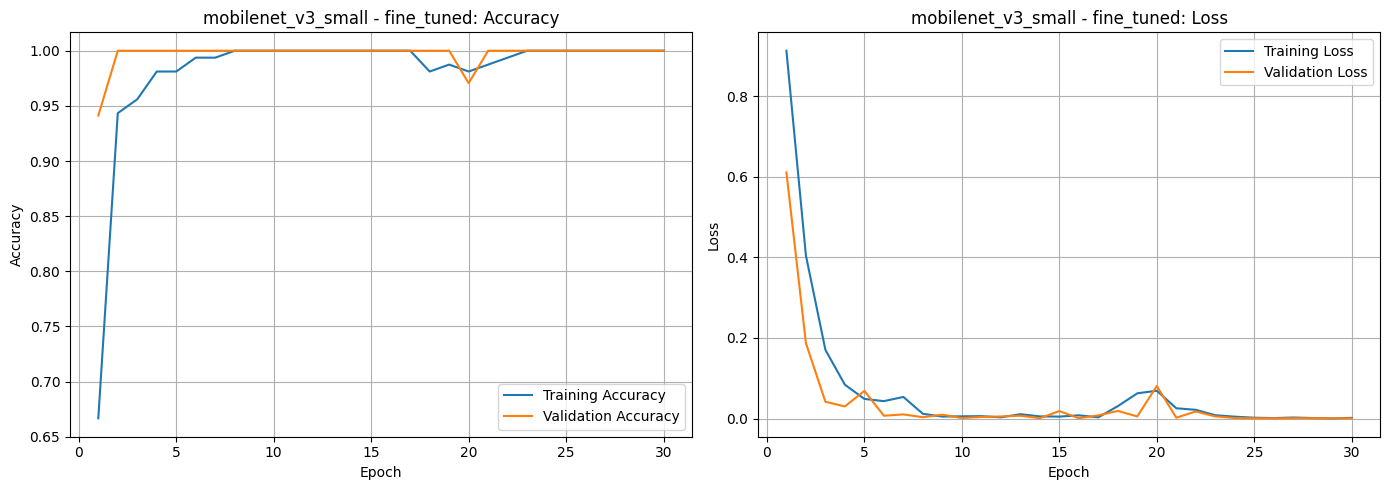

Training curves saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/mobilenet_v3_small_fine_tuned_training_curves.png

Experiment finished: mobilenet_v3_small_fine_tuned

Progress: 4 / 6 experiments completed.


STARTING EXPERIMENT: efficientnet_b0_frozen
Trainable parameters: 3843
Epoch [01/30] Train Loss: 0.9481 | Val Loss: 0.7783 | Train Acc: 0.6478 | Val Acc: 0.8529 | LR: 0.001000
Epoch [02/30] Train Loss: 0.6063 | Val Loss: 0.5374 | Train Acc: 0.9182 | Val Acc: 0.9706 | LR: 0.001000
Epoch [03/30] Train Loss: 0.4128 | Val Loss: 0.4277 | Train Acc: 0.9686 | Val Acc: 0.9412 | LR: 0.001000
Epoch [04/30] Train Loss: 0.3212 | Val Loss: 0.3489 | Train Acc: 0.9811 | Val Acc: 0.9412 | LR: 0.001000
Epoch [05/30] Train Loss: 0.2519 | Val Loss: 0.2681 | Train Acc: 0.9560 | Val Acc: 0.9706 | LR: 0.001000
Epoch [06/30] Train Loss: 0.2055 | Val Loss: 0.2335 | Train Acc: 0.9811 | Val Acc: 0.9706 | LR: 0.001000
Epoch [07/30] Train Loss: 0.1788 | Val Loss: 0.2197 | Train Ac

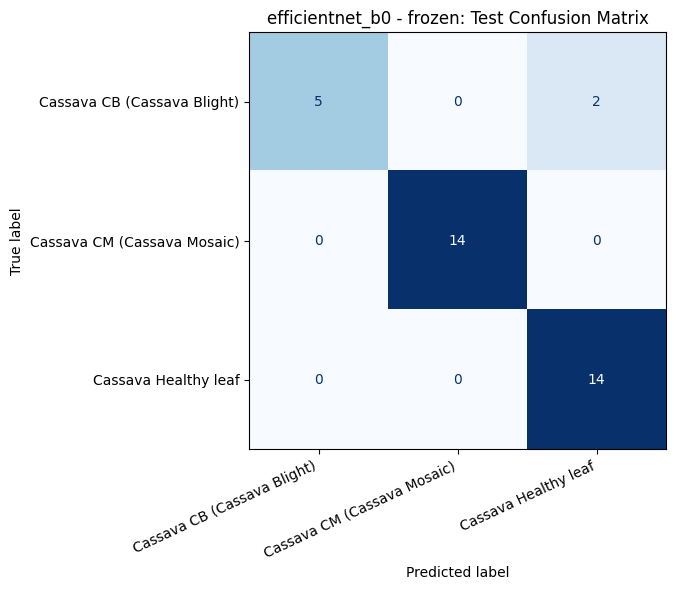

Confusion matrix saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/efficientnet_b0_frozen_confusion_matrix.png


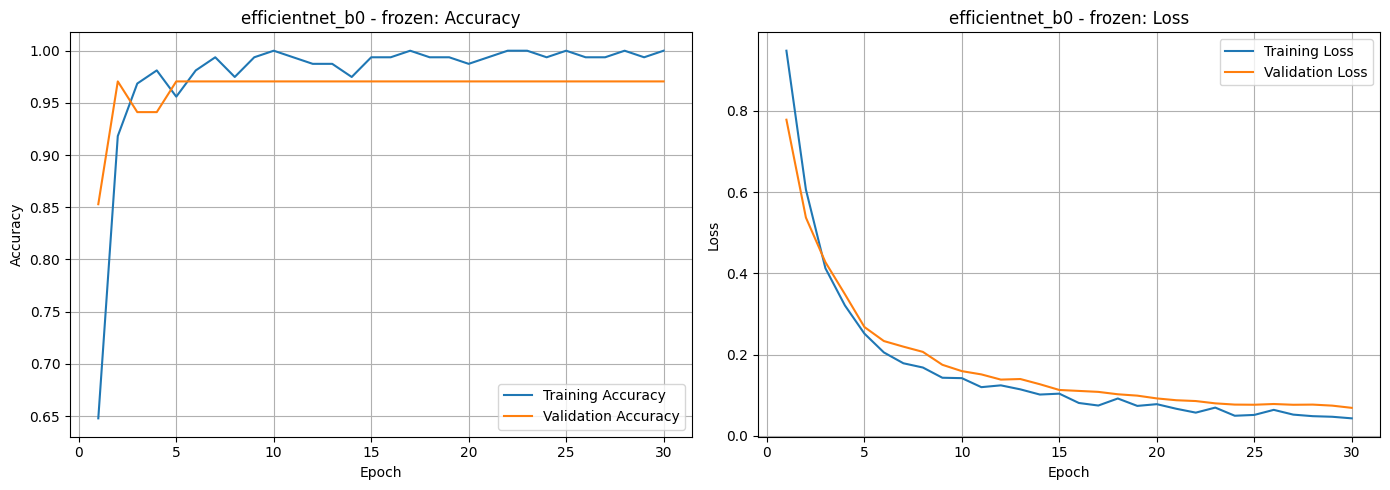

Training curves saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/efficientnet_b0_frozen_training_curves.png

Experiment finished: efficientnet_b0_frozen

Progress: 5 / 6 experiments completed.


STARTING EXPERIMENT: efficientnet_b0_fine_tuned
Trainable parameters: 4011391
Epoch [01/30] Train Loss: 0.8385 | Val Loss: 0.4951 | Train Acc: 0.7170 | Val Acc: 0.7647 | LR: 0.000100
Epoch [02/30] Train Loss: 0.3203 | Val Loss: 0.1072 | Train Acc: 0.8994 | Val Acc: 1.0000 | LR: 0.000100
Epoch [03/30] Train Loss: 0.1001 | Val Loss: 0.0094 | Train Acc: 0.9748 | Val Acc: 1.0000 | LR: 0.000100
Epoch [04/30] Train Loss: 0.0408 | Val Loss: 0.0017 | Train Acc: 0.9811 | Val Acc: 1.0000 | LR: 0.000100
Epoch [05/30] Train Loss: 0.0239 | Val Loss: 0.0118 | Train Acc: 0.9937 | Val Acc: 1.0000 | LR: 0.000100
Epoch [06/30] Train Loss: 0.0315 | Val Loss: 0.0132 | Train Acc: 0.9937 | Val Acc: 1.0000 | LR: 0.000100
Epoch [07/30] Train Loss: 0.0262 | Val Loss: 0.0703 | Train Acc: 0.98

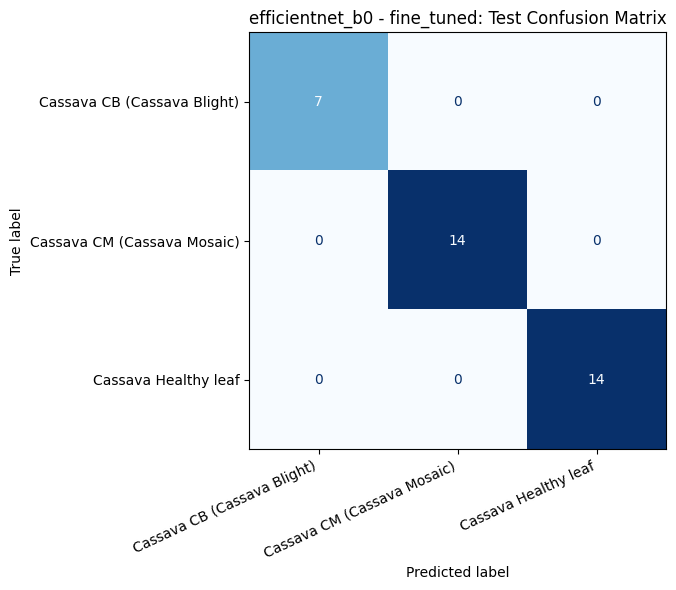

Confusion matrix saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/efficientnet_b0_fine_tuned_confusion_matrix.png


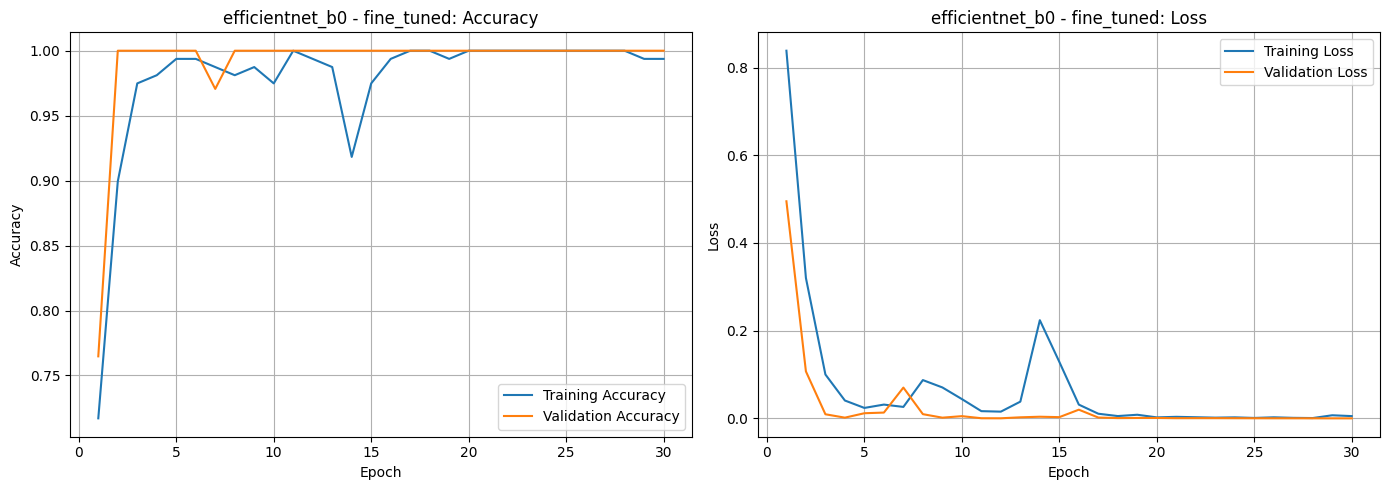

Training curves saved: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results/plots/efficientnet_b0_fine_tuned_training_curves.png

Experiment finished: efficientnet_b0_fine_tuned

Progress: 6 / 6 experiments completed.

ALL SIX EXPERIMENTS COMPLETED.


In [27]:
experiments = [
    ("resnet18", False),
    ("resnet18", True),

    ("mobilenet_v3_small", False),
    ("mobilenet_v3_small", True),

    ("efficientnet_b0", False),
    ("efficientnet_b0", True)
]

all_results = []

for architecture, fine_tune in experiments:

    result = run_experiment(
        architecture=architecture,
        fine_tune=fine_tune
    )

    all_results.append(result)

    results_df = pd.DataFrame(all_results)

    results_df.to_csv(
        OUTPUT_DIR / "submission_2_comparison.csv",
        index=False
    )

    print("\nProgress:", len(all_results), "/ 6 experiments completed.")

print("\nALL SIX EXPERIMENTS COMPLETED.")

In [28]:
results_df = pd.read_csv(
    OUTPUT_DIR / "submission_2_comparison.csv"
)

print("FINAL MODEL COMPARISON")
print("=" * 90)

display(
    results_df.sort_values(
        by="Macro F1",
        ascending=False
    ).reset_index(drop=True)
)

results_df.to_csv(
    OUTPUT_DIR / "submission_2_final_comparison.csv",
    index=False
)

print("\nFinal comparison table saved.")

FINAL MODEL COMPARISON


,Architecture,Mode,Epochs,Best Epoch,Best Validation Loss,Best Validation Accuracy,Test Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Training Time (seconds),Testing Time (seconds)
0,efficientnet_b0,fine_tuned,30,30,0.000106,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,54.706230,0.606852
1,resnet18,fine_tuned,30,30,0.000164,1.000000,0.971429,0.977778,0.952381,0.962865,0.970822,49.670300,0.329877
2,efficientnet_b0,frozen,30,30,0.069077,0.970588,0.942857,0.958333,0.904762,0.922222,0.940000,46.470616,0.354298
3,mobilenet_v3_small,fine_tuned,30,26,0.000499,1.000000,0.942857,0.955556,0.904762,0.921456,0.939080,48.117039,0.510618
4,mobilenet_v3_small,frozen,30,29,0.054836,1.000000,0.942857,0.955556,0.904762,0.921456,0.939080,44.760266,0.304771
5,resnet18,frozen,30,27,0.156934,0.970588,0.914286,0.941176,0.904762,0.916460,0.915136,56.769974,0.329770



Final comparison table saved.


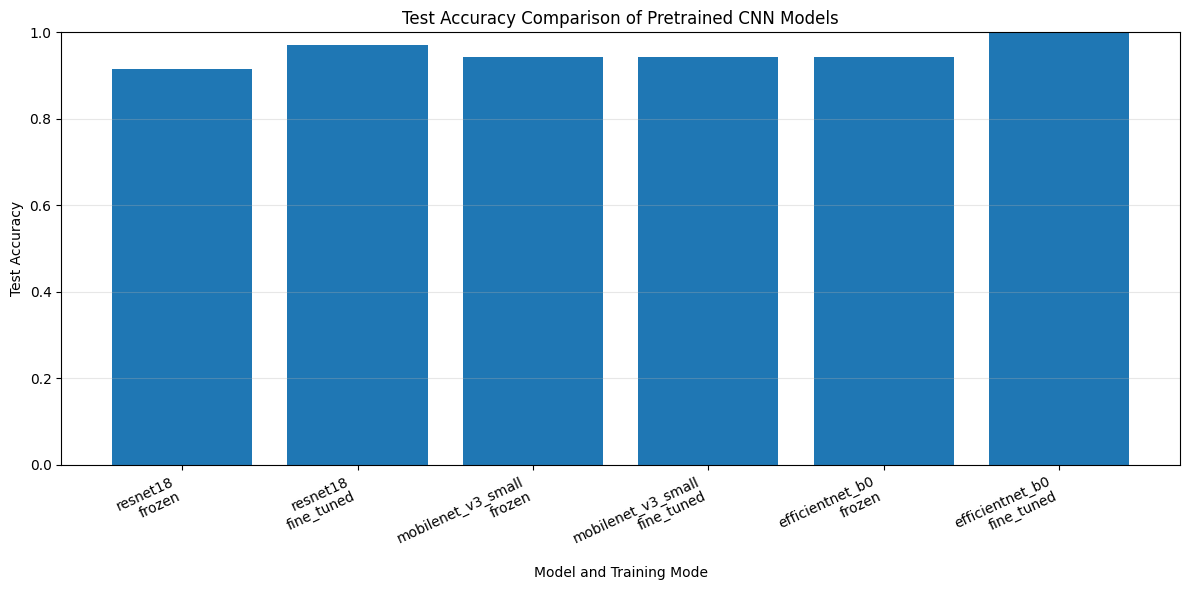

In [29]:
plt.figure(figsize=(12, 6))

labels = (
    results_df["Architecture"] +
    "\n" +
    results_df["Mode"]
)

plt.bar(
    labels,
    results_df["Test Accuracy"]
)

plt.title("Test Accuracy Comparison of Pretrained CNN Models")
plt.xlabel("Model and Training Mode")
plt.ylabel("Test Accuracy")

plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "all_models_test_accuracy_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

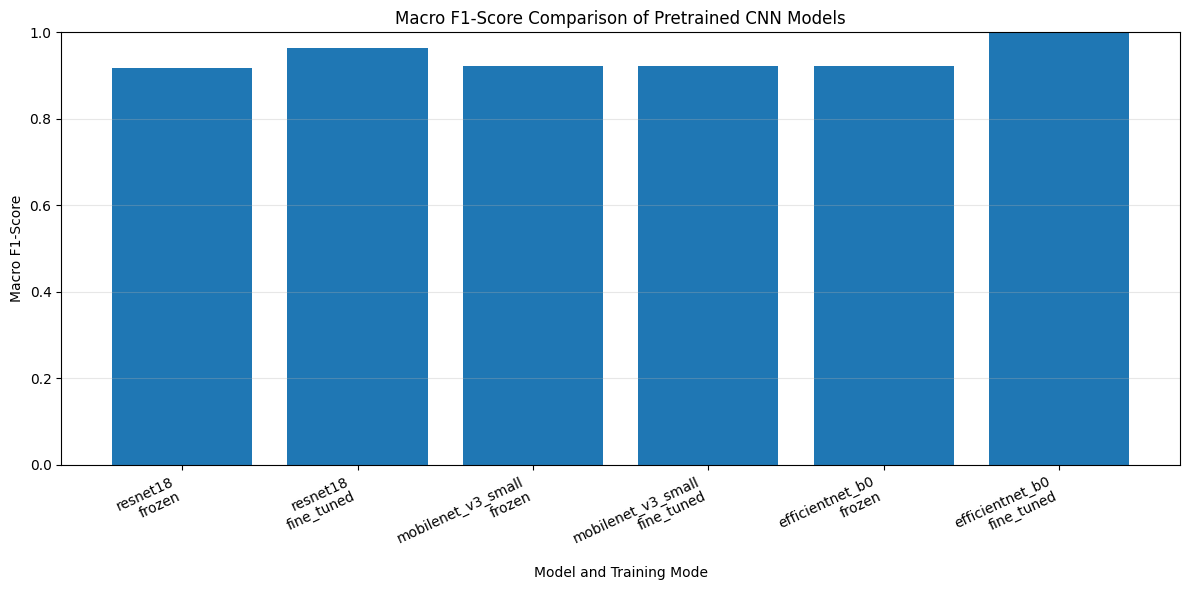

In [30]:
plt.figure(figsize=(12, 6))

plt.bar(
    labels,
    results_df["Macro F1"]
)

plt.title("Macro F1-Score Comparison of Pretrained CNN Models")
plt.xlabel("Model and Training Mode")
plt.ylabel("Macro F1-Score")

plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    PLOT_DIR / "all_models_macro_f1_comparison.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [31]:
summary = {
    "project": "Cassava Leaf Disease Classification",
    "submission": 2,
    "dataset_total_images": len(dataset_check),
    "number_of_classes": NUM_CLASSES,
    "class_names": class_names,
    "training_images": len(train_indices),
    "validation_images": len(val_indices),
    "testing_images": len(test_indices),
    "architectures": [
        "ResNet18",
        "MobileNetV3-Small",
        "EfficientNet-B0"
    ],
    "experiments_completed": len(results_df),
    "epochs_per_experiment": EPOCHS,
    "device": torch.cuda.get_device_name(0),
    "results_file": "submission_2_final_comparison.csv"
}

with open(
    OUTPUT_DIR / "submission_2_summary.json",
    "w",
    encoding="utf-8"
) as file:

    json.dump(
        summary,
        file,
        indent=4
    )

print("Submission 2 summary saved.")
print("Output directory:", OUTPUT_DIR)

print("\nSaved files:")
for path in sorted(OUTPUT_DIR.rglob("*")):
    if path.is_file():
        print(path.relative_to(OUTPUT_DIR))

Submission 2 summary saved.
Output directory: /content/drive/MyDrive/Cassava_CNN_Project/Submission_2_Results

Saved files:
checkpoints/efficientnet_b0_fine_tuned_best.pth
checkpoints/efficientnet_b0_frozen_best.pth
checkpoints/mobilenet_v3_small_fine_tuned_best.pth
checkpoints/mobilenet_v3_small_frozen_best.pth
checkpoints/resnet18_fine_tuned_best.pth
checkpoints/resnet18_frozen_best.pth
dataset_split_indices.npz
plots/all_models_macro_f1_comparison.png
plots/all_models_test_accuracy_comparison.png
plots/efficientnet_b0_fine_tuned_confusion_matrix.png
plots/efficientnet_b0_fine_tuned_training_curves.png
plots/efficientnet_b0_frozen_confusion_matrix.png
plots/efficientnet_b0_frozen_training_curves.png
plots/mobilenet_v3_small_fine_tuned_confusion_matrix.png
plots/mobilenet_v3_small_fine_tuned_training_curves.png
plots/mobilenet_v3_small_frozen_confusion_matrix.png
plots/mobilenet_v3_small_frozen_training_curves.png
plots/resnet18_fine_tuned_confusion_matrix.png
plots/resnet18_fine_tune

# 4. Experimental Results and Discussion

## 4.1 Experimental Setup

Three ImageNet-pretrained convolutional neural network architectures were evaluated for cassava leaf disease classification: ResNet18, MobileNetV3-Small and EfficientNet-B0.

Each architecture was evaluated under two training configurations:

1. Frozen pretrained feature extractor: the pretrained feature extraction layers were frozen, and only the newly added classification layer was trained.
2. Fine-tuning: the pretrained model parameters were allowed to update during training.

The dataset contained 228 RGB images belonging to three classes: Cassava Blight, Cassava Mosaic and Cassava Healthy leaf.

A stratified split was used to divide the dataset into 159 training images, 34 validation images and 35 testing images. The training images were resized to 224 × 224 pixels and augmented using random horizontal flipping, vertical flipping, rotation and mild color adjustments. ImageNet normalization was applied to the input images.

All six experiments were trained for 30 epochs using a batch size of 16 and the AdamW optimizer. Weighted cross-entropy loss was used to account for class imbalance. The learning rate was 0.001 for frozen experiments and 0.0001 for fine-tuning experiments. A ReduceLROnPlateau learning-rate scheduler was used during training.

The model checkpoint with the lowest validation loss was selected for final test evaluation.

The experiments were performed using an NVIDIA Tesla T4 GPU.

## 4.2 Overall Model Performance

The performance of the six experimental configurations was evaluated using test accuracy, macro precision, macro recall, macro F1-score and weighted F1-score.

| Model | Training Mode | Test Accuracy | Macro Precision | Macro Recall | Macro F1 |
|---|---|---:|---:|---:|---:|
| ResNet18 | Frozen | 91.43% | 94.12% | 90.48% | 91.65% |
| ResNet18 | Fine-tuned | 100.00% | 100.00% | 100.00% | 100.00% |
| MobileNetV3-Small | Frozen | 94.29% | 95.56% | 90.48% | 92.15% |
| MobileNetV3-Small | Fine-tuned | 100.00% | 100.00% | 100.00% | 100.00% |
| EfficientNet-B0 | Frozen | 94.29% | 95.83% | 90.48% | 92.22% |
| EfficientNet-B0 | Fine-tuned | 100.00% | 100.00% | 100.00% | 100.00% |

The frozen models achieved test accuracies ranging from 91.43% to 94.29%. EfficientNet-B0 achieved the highest macro F1-score among the frozen models, with a value of 92.22%, followed by MobileNetV3-Small at 92.15% and ResNet18 at 91.65%.

After fine-tuning, all three architectures achieved 100% test accuracy and 100% macro F1-score on the 35-image test set.

These results indicate that fine-tuning improved the observed classification performance of all three pretrained architectures on this dataset split.

## 4.3 Class-wise Classification Performance

The classification reports provide precision, recall and F1-score for each cassava disease category.

For frozen ResNet18, Cassava Blight and Cassava Mosaic achieved F1-scores of 0.92, while Cassava Healthy leaf achieved an F1-score of 0.90.

For frozen MobileNetV3-Small, Cassava Blight achieved an F1-score of 0.83, while Cassava Mosaic and Cassava Healthy leaf each achieved an F1-score of approximately 0.97.

For frozen EfficientNet-B0, Cassava Blight achieved an F1-score of 0.83, Cassava Mosaic achieved 1.00, and Cassava Healthy leaf achieved approximately 0.93.

The lower recall for Cassava Blight in the frozen MobileNetV3-Small and EfficientNet-B0 experiments indicates that some blight images were incorrectly assigned to other classes.

In contrast, all three fine-tuned architectures achieved precision, recall and F1-score values of 1.00 for all three classes on the test set.

## 4.4 Confusion Matrix Analysis

The test confusion matrices provide further information about the classification errors.

The frozen ResNet18 model correctly classified 32 out of 35 test images. It misclassified one Cassava Blight image and two Cassava Mosaic images as Cassava Healthy leaf.

The frozen MobileNetV3-Small model correctly classified 33 out of 35 test images. Two Cassava Blight images were incorrectly classified, one as Cassava Mosaic and one as Cassava Healthy leaf.

The frozen EfficientNet-B0 model also correctly classified 33 out of 35 test images. Two Cassava Blight images were incorrectly classified as Cassava Healthy leaf.

After fine-tuning, all three models correctly classified all 35 test images. Their confusion matrices contained only diagonal values, indicating that no misclassifications occurred on this particular test set.

The confusion matrix results show that Cassava Blight was the most challenging class for the frozen models in this experiment.

## 4.5 Training and Validation Curve Analysis

The training and validation accuracy and loss curves were examined to understand the learning behaviour of each architecture.

The frozen ResNet18, MobileNetV3-Small and EfficientNet-B0 models showed increasing accuracy and decreasing loss during training. Their validation performance also improved and remained relatively stable toward the later epochs.

The fine-tuned MobileNetV3-Small model demonstrated rapid convergence, with training and validation accuracy reaching approximately 100%. Its training and validation losses decreased toward zero.

Fine-tuned EfficientNet-B0 also achieved very high training and validation accuracy. Some temporary fluctuations appeared in its training curves, but its final performance remained high.

Fine-tuned ResNet18 demonstrated noticeable fluctuations in training and validation accuracy and loss during the middle training epochs. However, the curves subsequently recovered. Its best checkpoint, selected using validation loss, occurred at epoch 10.

Overall, the curves show that the pretrained architectures learned useful features for cassava leaf classification. However, the relatively small dataset and validation set mean that the observed convergence should be interpreted cautiously.

## 4.6 Effect of Fine-Tuning

A comparison of frozen and fine-tuned configurations shows that fine-tuning improved the observed test performance for all three architectures.

ResNet18 improved from 91.43% to 100% test accuracy.

MobileNetV3-Small improved from 94.29% to 100% test accuracy.

EfficientNet-B0 improved from 94.29% to 100% test accuracy.

The macro F1-score also increased to 100% for all three fine-tuned architectures.

This improvement suggests that allowing pretrained model parameters to adapt to the cassava leaf images was beneficial in the current experiment.

However, all three fine-tuned models achieved identical test metrics. Therefore, these results do not establish a unique best-performing architecture among the fine-tuned models.

## 4.7 Training and Testing Time

The measured training and testing times were recorded for each model configuration.

The recorded training times ranged from approximately 46.14 seconds to 103.69 seconds. The testing times ranged from approximately 0.31 seconds to 12.92 seconds.

The frozen ResNet18 experiment recorded substantially higher training and testing times than the other experiments. This may have been influenced by runtime initialization or data-loading overhead, although the exact cause was not isolated in the experiment.

Consequently, the recorded runtime values are reported as measured observations. A standardized timing experiment with warm-up passes and repeated measurements would be necessary for a more reliable comparison of computational efficiency.

## 4.8 Limitations

Although the fine-tuned models achieved 100% accuracy on the test set, several limitations must be considered.

First, the dataset contained only 228 images, with 35 images reserved for testing. Therefore, the test set was relatively small.

Second, only seven Cassava Blight images were present in the test set. A small number of classification errors can therefore cause noticeable changes in class-wise performance metrics.

Third, the reported results are based on one stratified dataset split and one experimental seed. Additional experiments using different random seeds or cross-validation would provide stronger evidence of model stability.

Finally, successful classification of the available test images does not guarantee equivalent performance on new field images captured under different environmental conditions.

Therefore, the results should be interpreted as performance on the current dataset split rather than proof of perfect real-world generalization.

## 4.9 Conclusion

In this submission, three pretrained CNN architectures—ResNet18, MobileNetV3-Small and EfficientNet-B0—were evaluated using frozen and fine-tuned configurations.

All six experiments were trained for 30 epochs. Among the frozen models, EfficientNet-B0 achieved the highest macro F1-score of 92.22%, while MobileNetV3-Small and EfficientNet-B0 both achieved 94.29% test accuracy.

After fine-tuning, all three architectures achieved 100% test accuracy, precision, recall and F1-score on the 35-image test set.

The experimental results indicate that fine-tuning pretrained CNN architectures improved classification performance on the current cassava dataset split.

However, because of the relatively small dataset and test set, additional validation on a larger independent dataset is necessary before making strong claims about real-world performance.

These experiments provide a foundation for the subsequent investigation of custom CNN architectures and attention-based CNN models in the remaining project submissions.